# Avance 2 de proyecto: asistente multimodal para un hospedaje vacacional
José Pablo Herrera Fernández · MBIA2602 Desarrollo de aplicaciones con IA · Tecmilenio

Continúa el chatbot basado en reglas del Avance 1 (`chatbot_hospedaje.py`). Este notebook agrega:
1. Proceso de NLP y clasificador de intenciones (TF-IDF con Naive Bayes y SVM).
2. Clasificador visual con CNN: una red desde cero y ResNet50 con transferencia de aprendizaje,
   como en la sesión del 12 de noviembre.
3. Integración texto-imagen: el huésped escribe y manda una foto; el sistema decide si responde o escala.

En Colab: `!git clone -b avance2 https://github.com/jospabloh/chatbot-hospedaje-nltk` y `%cd chatbot-hospedaje-nltk/avance2`.

In [1]:
import json, os, re, unicodedata, random
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.tokenize import wordpunct_tokenize
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
os.makedirs("salidas", exist_ok=True)
nltk.download("stopwords", quiet=True)
SUMMARY = {}

## 1. Conjunto de datos textual

In [2]:
corpus = pd.read_csv("datos/corpus_intenciones.csv", sep="|")
out_of_scope = pd.read_csv("datos/fuera_de_alcance.csv", sep="|")
print("Frases:", len(corpus), "| Intenciones:", corpus["intencion"].nunique())
print(corpus["intencion"].value_counts().to_string())
SUMMARY["corpus"] = {"frases": len(corpus), "intenciones": int(corpus["intencion"].nunique()),
                     "por_intencion": corpus["intencion"].value_counts().to_dict()}
corpus.sample(8, random_state=SEED)

Frases: 681 | Intenciones: 14
intencion
servicios                 73
ubicacion                 62
cerradura                 62
porton_estacionamiento    55
contactar_anfitrion       53
saludo_cortesia           50
llegada_tarde             50
early_late_checkout       50
reportar_problema         48
horarios                  45
tarifas                   36
acceso_fraccionamiento    35
disponibilidad            32
reglas                    30


,texto,intencion
648,se puede facturar con tarifa empresarial,contactar_anfitrion
296,se puede estacionar adentro,porton_estacionamiento
63,me cotizas 2 noches para 4,tarifas
320,tienen cafetera,servicios
101,para cuando tienen libre,disponibilidad
354,puedo meter bocina,reglas
286,el porton se abrio a medias,porton_estacionamiento
340,la casa tiene calefaccion,servicios


## 2. Preprocesamiento: normalización, tokenización, stopwords y stemming
Se conservan las palabras de pregunta y de negación (*no, cuánto, dónde, antes, más*): en este dominio
distinguen intenciones ("¿cuánto?" es tarifa, "¿dónde?" es ubicación, "no abre" es una falla).

In [3]:
KEEP_WORDS = {"no", "cuanto", "cuantos", "cuanta", "donde", "como", "cuando", "antes", "mas", "hasta",
             "desde", "sin", "que", "hay", "puedo", "tarde", "temprano"}
STOPWORDS_ES = {unicodedata.normalize("NFD", w).encode("ascii", "ignore").decode() for w in stopwords.words("spanish")}
STOPWORDS_ES -= KEEP_WORDS
stemmer_es = SnowballStemmer("spanish")


def normalize(text: str) -> str:
    """Minúsculas, sin acentos (conserva la ñ), sin signos y sin letras repetidas de más ("holaaa")."""
    text = text.lower().replace("ñ", "\0")
    text = "".join(c for c in unicodedata.normalize("NFD", text) if unicodedata.category(c) != "Mn")
    text = text.replace("\0", "ñ")
    text = re.sub(r"(.)\1{2,}", r"\1", text)
    return re.sub(r"[^a-zñ0-9 ]", " ", text)


def preprocess(text: str, stem: bool = True, remove_stopwords: bool = True) -> str:
    tokens = [t for t in wordpunct_tokenize(normalize(text)) if t.isalnum()]
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOPWORDS_ES]
    if stem:
        tokens = [stemmer_es.stem(t) for t in tokens]
    return " ".join(tokens)


examples = ["¿Cuánto cuesta la noche?", "No me abre la chapa!!", "Holaaa, ¿a qué hora es el check-in?",
            "El portón eléctrico no responde"]
preprocessing_table = pd.DataFrame([{"original": e, "normalizado": normalize(e).strip(),
                           "tokens": wordpunct_tokenize(normalize(e)),
                           "sin_stopwords": preprocess(e, stem=False),
                           "stemming": preprocess(e)} for e in examples])
preprocessing_table.to_csv("salidas/ejemplos_preprocesamiento.csv", index=False)
preprocessing_table

,original,normalizado,tokens,sin_stopwords,stemming
0,¿Cuánto cuesta la noche?,cuanto cuesta la noche,"[cuanto, cuesta, la, noche]",cuanto cuesta noche,cuant cuest noch
1,No me abre la chapa!!,no me abre la chapa,"[no, me, abre, la, chapa]",no abre chapa,no abre chap
2,"Holaaa, ¿a qué hora es el check-in?",hola a que hora es el check in,"[hola, a, que, hora, es, el, check, in]",hola que hora check in,hol que hor check in
3,El portón eléctrico no responde,el porton electrico no responde,"[el, porton, electrico, no, responde]",porton electrico no responde,porton electr no respond


## 3. Representación TF-IDF y clasificación de intenciones
Dos bloques TF-IDF unidos: palabras y bigramas sobre el texto ya procesado (sin stopwords y con stemming),
y n-gramas de caracteres (2 a 5) sobre el texto normalizado, que toleran errores de dedo ("disponoble", "chekin").
División estratificada 80/20; validación cruzada de 5 particiones sobre el entrenamiento.

In [4]:
from sklearn.compose import ColumnTransformer

corpus["norm"] = corpus["texto"].map(lambda t: preprocess(t, stem=False, remove_stopwords=False))
corpus["proc"] = corpus["texto"].map(preprocess)
X = corpus[["norm", "proc"]]
X_tr, X_te, y_tr, y_te = train_test_split(X, corpus["intencion"], test_size=0.2,
                                          random_state=SEED, stratify=corpus["intencion"])


def tfidf():
    return ColumnTransformer([
        ("palabras", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True), "proc"),
        ("caracteres", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True), "norm")])


candidates = {"Naive Bayes": MultinomialNB(alpha=0.1), "SVM lineal": LinearSVC(C=0.5, random_state=SEED)}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
text_results = []
for model_name, clf in candidates.items():
    pipe = make_pipeline(tfidf(), clf)
    cvs = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="f1_macro")
    pred = pipe.fit(X_tr, y_tr).predict(X_te)
    text_results.append({"modelo": model_name, "f1_macro_cv": cvs.mean(), "f1_macro_cv_std": cvs.std(),
                      "accuracy_prueba": accuracy_score(y_te, pred), "f1_macro_prueba": f1_score(y_te, pred, average="macro")})
text_results = pd.DataFrame(text_results)
dims = tfidf().fit(X_tr).transform(X_tr.iloc[:1]).shape[1]
print("Dimensión de la representación TF-IDF:", dims)
text_results.round(3)

Dimensión de la representación TF-IDF: 7703


,modelo,f1_macro_cv,f1_macro_cv_std,accuracy_prueba,f1_macro_prueba
0,Naive Bayes,0.660,0.059,0.745,0.737
1,SVM lineal,0.706,0.054,0.730,0.723


### Efecto de cada paso del preprocesamiento (SVM con TF-IDF de palabras, mismo corte)

In [5]:
ablation = []
for variant, kw in [("Texto crudo", None), ("Normalizado y tokenizado", dict(stem=False, remove_stopwords=False)),
                     ("+ sin stopwords", dict(stem=False, remove_stopwords=True)),
                     ("+ stemming", dict(stem=True, remove_stopwords=True))]:
    txt = corpus["texto"] if kw is None else corpus["texto"].map(lambda t: preprocess(t, **kw))
    p = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True), LinearSVC(C=0.5, random_state=SEED))
    p.fit(txt.loc[X_tr.index], y_tr)
    pr = p.predict(txt.loc[X_te.index])
    ablation.append({"variante": variant, "accuracy": accuracy_score(y_te, pr), "f1_macro": f1_score(y_te, pr, average="macro")})
pr = make_pipeline(tfidf(), LinearSVC(C=0.5, random_state=SEED)).fit(X_tr, y_tr).predict(X_te)
ablation.append({"variante": "+ n-gramas de caracteres (final)", "accuracy": accuracy_score(y_te, pr), "f1_macro": f1_score(y_te, pr, average="macro")})
ablation = pd.DataFrame(ablation)
ablation.round(3)

,variante,accuracy,f1_macro
0,Texto crudo,0.657,0.633
1,Normalizado y tokenizado,0.657,0.633
2,+ sin stopwords,0.657,0.623
3,+ stemming,0.664,0.645
4,+ n-gramas de caracteres (final),0.730,0.723


### Modelo elegido: SVM lineal calibrada (entrega probabilidades para el umbral de confianza)

                        precision    recall  f1-score   support

acceso_fraccionamiento      0.444     0.571     0.500         7
             cerradura      0.800     0.923     0.857        13
   contactar_anfitrion      0.778     0.636     0.700        11
        disponibilidad      0.833     0.833     0.833         6
   early_late_checkout      0.667     0.800     0.727        10
              horarios      0.857     0.667     0.750         9
         llegada_tarde      0.571     0.800     0.667        10
porton_estacionamiento      0.909     0.909     0.909        11
                reglas      1.000     0.667     0.800         6
     reportar_problema      0.636     0.700     0.667        10
       saludo_cortesia      1.000     0.900     0.947        10
             servicios      0.750     0.800     0.774        15
               tarifas      0.667     0.571     0.615         7
             ubicacion      0.875     0.583     0.700        12

              accuracy                

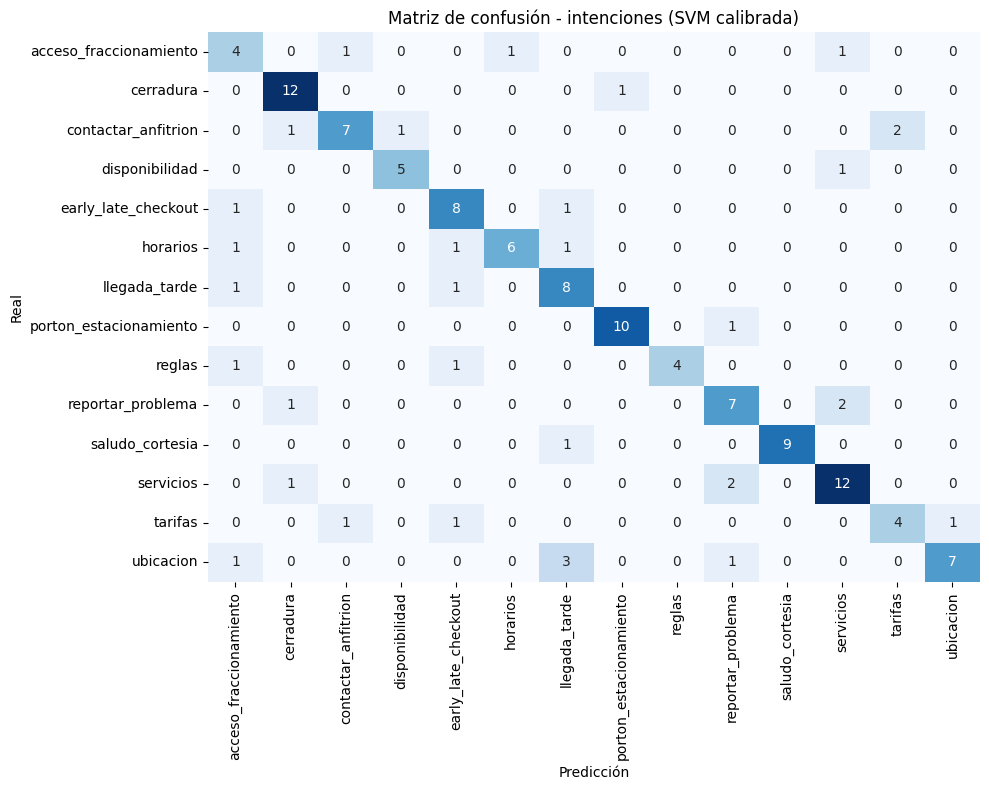

,texto,real,pred
366,cobran multa si hay danos,reglas,early_late_checkout
69,cobran extra por mascota,tarifas,early_late_checkout
21,hasta luego,saludo_cortesia,llegada_tarde
213,hay que registrarse en la entrada,acceso_fraccionamiento,horarios
399,entrada anticipada es posible?,early_late_checkout,acceso_fraccionamiento
451,me das el numero de la dueña,contactar_anfitrion,cerradura
64,que tan caro es,tarifas,ubicacion
410,hay una fuga en la cocina,reportar_problema,servicios
677,si reservamos seguido hay mejor precio,contactar_anfitrion,tarifas
650,hay descuento si reservo las 4 unidades,contactar_anfitrion,disponibilidad


In [6]:
text_clf = make_pipeline(tfidf(), CalibratedClassifierCV(LinearSVC(C=0.5, random_state=SEED), cv=5))
text_clf.fit(X_tr, y_tr)
pred_te = text_clf.predict(X_te)
text_report = classification_report(y_te, pred_te, zero_division=0, output_dict=True)
print(classification_report(y_te, pred_te, zero_division=0, digits=3))
intent_labels = sorted(corpus["intencion"].unique())
plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(y_te, pred_te, labels=intent_labels), annot=True, fmt="d", cmap="Blues",
            xticklabels=intent_labels, yticklabels=intent_labels, cbar=False)
plt.title("Matriz de confusión - intenciones (SVM calibrada)"); plt.xlabel("Predicción"); plt.ylabel("Real")
plt.tight_layout(); plt.savefig("salidas/cm_texto.png", dpi=160); plt.show()
errors = pd.DataFrame({"texto": corpus.loc[X_te.index, "texto"], "real": y_te, "pred": pred_te})
errors = errors[errors.real != errors.pred]
errors.to_csv("salidas/errores_texto.csv", index=False)
errors

### Umbral de confianza: lo que el modelo no reconoce se escala a la anfitriona, no se adivina

In [7]:
TEXT_THRESHOLD = 0.40


def to_features(text: str) -> pd.DataFrame:
    return pd.DataFrame({"norm": [preprocess(text, stem=False, remove_stopwords=False)], "proc": [preprocess(text)]})


def classify_text(text: str):
    prob = text_clf.predict_proba(to_features(text))[0]
    i = int(np.argmax(prob))
    return text_clf.classes_[i], float(prob[i])


test_conf = text_clf.predict_proba(X_te).max(axis=1)
is_correct = (pred_te == y_te.values)
out_of_scope_conf = np.array([classify_text(t)[1] for t in out_of_scope["texto"]])
thresholds = pd.DataFrame([{"umbral": u, "cobertura": (test_conf >= u).mean(),
                          "accuracy_cubierta": is_correct[test_conf >= u].mean(),
                          "fuera_de_alcance_escalado": (out_of_scope_conf < u).mean()} for u in [0.2, 0.3, 0.4, 0.5]])
print(thresholds.round(3).to_string(index=False))
pd.DataFrame([(t, *classify_text(t)) for t in out_of_scope["texto"]], columns=["texto", "intencion", "confianza"]).round(2)

 umbral  cobertura  accuracy_cubierta  fuera_de_alcance_escalado
    0.2      0.993              0.750                      0.000
    0.3      0.927              0.764                      0.000
    0.4      0.832              0.816                      0.125
    0.5      0.664              0.879                      0.375


,texto,intencion,confianza
0,recomiendan algun restaurante por aca,servicios,0.55
1,que lugares hay para visitar,porton_estacionamiento,0.40
2,donde puedo comprar despensa cerca,ubicacion,0.53
3,saben si hay farmacia cerca,ubicacion,0.44
4,como esta el clima alla,reportar_problema,0.53
5,me pueden recomendar un taxi de confianza,contactar_anfitrion,0.34
6,hay gimnasio cerca,ubicacion,0.64
7,a que hora abre el super,horarios,0.75


In [8]:
row = thresholds[thresholds.umbral == TEXT_THRESHOLD].iloc[0]
SUMMARY["texto"] = {"dimension_tfidf": int(dims), "modelos": text_results.round(4).to_dict("records"),
                    "ablacion": ablation.round(4).to_dict("records"),
                    "svm_calibrada": {"accuracy": accuracy_score(y_te, pred_te), "f1_macro": f1_score(y_te, pred_te, average="macro")},
                    "por_intencion": {k: v for k, v in text_report.items() if k in intent_labels},
                    "n_prueba": len(y_te), "errores": errors.to_dict("records"),
                    "umbral": TEXT_THRESHOLD, "umbrales": thresholds.round(4).to_dict("records")}

## 4. Conjunto de imágenes
Cinco clases que corresponden a lo que un huésped fotografía cuando algo no le abre o no funciona:
`cerradura` (chapa electrónica), `porton` (portón del estacionamiento), `caseta` (acceso del fraccionamiento),
`controles` (minisplit, termostato, control remoto) e `interior` (recámara, sala, cocina).
Las imágenes son de Wikimedia Commons con licencia libre (créditos en `datos/creditos_imagenes.csv`), revisadas a mano.
Se quitan casi duplicados con un hash perceptual antes de dividir, para que la prueba no vea fotos "gemelas" del entrenamiento.

/Users/jphf/haru-work/tec-avance2/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Imágenes únicas: 256
cerradura    52
porton       49
caseta       45
controles    50
interior     60
Entrenamiento: 179 | Validación: 38 | Prueba: 39


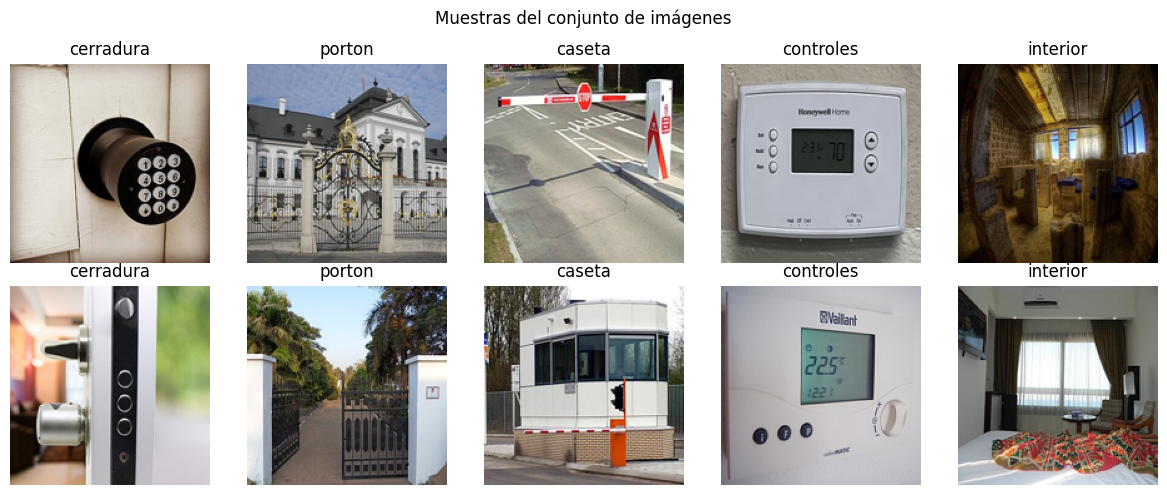

In [9]:
import glob
from PIL import Image
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

tf.random.set_seed(SEED)
CLASSES = ["cerradura", "porton", "caseta", "controles", "interior"]
IMG_SIZE = 160


def ahash(path, n=8):
    im = Image.open(path).convert("L").resize((n, n))
    a = np.asarray(im, dtype=np.float32)
    return tuple((a > a.mean()).flatten())


paths, image_labels, seen = [], [], {}
for k, c in enumerate(CLASSES):
    for r in sorted(glob.glob(f"datos/imagenes/{c}/*.jpg")):
        h = ahash(r)
        if h in seen:
            continue
        seen[h] = r
        paths.append(r); image_labels.append(k)
paths, image_labels = np.array(paths), np.array(image_labels)
image_counts = pd.Series([CLASSES[i] for i in image_labels]).value_counts().reindex(CLASSES)
print("Imágenes únicas:", len(paths)); print(image_counts.to_string())

r_tr, r_tmp, e_tr, e_tmp = train_test_split(paths, image_labels, test_size=0.30, random_state=SEED, stratify=image_labels)
r_va, r_te, e_va, e_te = train_test_split(r_tmp, e_tmp, test_size=0.50, random_state=SEED, stratify=e_tmp)
print("Entrenamiento:", len(r_tr), "| Validación:", len(r_va), "| Prueba:", len(r_te))


def load_images(image_paths):
    return np.stack([np.asarray(Image.open(r).convert("RGB").resize((IMG_SIZE, IMG_SIZE)), dtype=np.float32) for r in image_paths])


x_tr, x_va, x_te = load_images(r_tr), load_images(r_va), load_images(r_te)
y_tr_c, y_va_c = tf.keras.utils.to_categorical(e_tr, 5), tf.keras.utils.to_categorical(e_va, 5)

plt.figure(figsize=(12, 5))
for i, k in enumerate(range(5)):
    idx = np.where(e_tr == k)[0][:2]
    for j, ii in enumerate(idx):
        plt.subplot(2, 5, j * 5 + i + 1); plt.imshow(x_tr[ii].astype("uint8")); plt.title(CLASSES[k]); plt.axis("off")
plt.suptitle("Muestras del conjunto de imágenes"); plt.tight_layout(); plt.savefig("salidas/muestras_imagenes.png", dpi=140); plt.show()

## 5. Clasificador visual
Igual que en la sesión del 12 de noviembre se comparan dos redes: una CNN entrenada desde cero y ResNet50
preentrenada en ImageNet con transferencia de aprendizaje. Ambas usan aumento de datos dentro del modelo
(volteo, rotación y zoom) y los mismos callbacks (EarlyStopping y ReduceLROnPlateau).

In [10]:
def augmentation():
    return tf.keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.08),
                                layers.RandomZoom(0.10)], name="aumento_de_datos")


def callbacks(patience=4):
    return [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)]


# CNN from scratch (same architecture as the class session, at 96x96). BatchNormalization with momentum 0.9:
# with ~6 batches per epoch the default (0.99) cannot estimate the statistics and validation
# stays flat on a single class (seen in the first run: constant 18 %).
inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = layers.Resizing(96, 96)(inputs)
x = layers.Rescaling(1 / 255.0)(x)
x = augmentation()(x)
for filters, dropout_rate in [(32, 0.25), (64, 0.30), (128, 0.40)]:
    x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x); x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x); x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.MaxPooling2D(2)(x); x = layers.Dropout(dropout_rate)(x)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x); x = layers.Dropout(0.5)(x)
cnn_model = models.Model(inputs, layers.Dense(5, activation="softmax")(x), name="CNN_desde_cero")
cnn_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
hist_cnn = cnn_model.fit(x_tr, y_tr_c, validation_data=(x_va, y_va_c), epochs=40, batch_size=32,
                         callbacks=callbacks(patience=10), verbose=2)  # more patience: it trains from scratch

Epoch 1/40


6/6 - 5s - 862ms/step - accuracy: 0.2793 - loss: 1.9099 - val_accuracy: 0.1842 - val_loss: 1.6973 - learning_rate: 0.0010


Epoch 2/40


6/6 - 3s - 435ms/step - accuracy: 0.4749 - loss: 1.3745 - val_accuracy: 0.1842 - val_loss: 2.1258 - learning_rate: 0.0010


Epoch 3/40


6/6 - 3s - 485ms/step - accuracy: 0.5307 - loss: 1.2191 - val_accuracy: 0.1842 - val_loss: 2.3039 - learning_rate: 0.0010


... (32 outputs left out)

Epoch 20/40


6/6 - 3s - 480ms/step - accuracy: 0.7821 - loss: 0.6393 - val_accuracy: 0.5263 - val_loss: 1.2438 - learning_rate: 1.5625e-05


Epoch 21/40


6/6 - 3s - 478ms/step - accuracy: 0.7709 - loss: 0.7054 - val_accuracy: 0.5000 - val_loss: 1.2505 - learning_rate: 1.5625e-05


In [11]:
# ResNet50 with transfer learning: frozen base, only the classification head is trained
base = ResNet50(weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False
inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
r = augmentation()(inputs)
r = layers.Lambda(preprocess_input, name="preprocesar_resnet")(r)
r = base(r, training=False)
r = layers.GlobalAveragePooling2D()(r)
r = layers.Dropout(0.40)(r)
resnet_model = models.Model(inputs, layers.Dense(5, activation="softmax")(r), name="ResNet50_transferencia")
resnet_model.compile(optimizer=tf.keras.optimizers.Adam(5e-4), loss="categorical_crossentropy", metrics=["accuracy"])
print("Parámetros entrenables:", sum(int(np.prod(w.shape)) for w in resnet_model.trainable_weights),
      "de", resnet_model.count_params())
hist_res = resnet_model.fit(x_tr, y_tr_c, validation_data=(x_va, y_va_c), epochs=15, batch_size=16,
                            callbacks=callbacks(), verbose=2)

Parámetros entrenables: 10245 de 23597957
Epoch 1/15


12/12 - 8s - 647ms/step - accuracy: 0.2682 - loss: 2.2474 - val_accuracy: 0.4211 - val_loss: 1.1381 - learning_rate: 5.0000e-04


Epoch 2/15


12/12 - 4s - 362ms/step - accuracy: 0.5475 - loss: 1.1852 - val_accuracy: 0.7895 - val_loss: 0.6966 - learning_rate: 5.0000e-04


Epoch 3/15


12/12 - 4s - 353ms/step - accuracy: 0.6536 - loss: 0.8869 - val_accuracy: 0.8421 - val_loss: 0.4499 - learning_rate: 5.0000e-04


... (16 outputs left out)

Epoch 12/15


12/12 - 4s - 357ms/step - accuracy: 0.9106 - loss: 0.2179 - val_accuracy: 0.8947 - val_loss: 0.3504 - learning_rate: 2.5000e-04


Epoch 13/15


12/12 - 4s - 374ms/step - accuracy: 0.9385 - loss: 0.2063 - val_accuracy: 0.8947 - val_loss: 0.3397 - learning_rate: 2.5000e-04


In [12]:
# Fine-tuning: the last block (conv5) is unfrozen with a low learning rate
base.trainable = True
for layer in base.layers:
    layer.trainable = layer.name.startswith("conv5") and not isinstance(layer, layers.BatchNormalization)
resnet_model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss="categorical_crossentropy", metrics=["accuracy"])
hist_ft = resnet_model.fit(x_tr, y_tr_c, validation_data=(x_va, y_va_c), epochs=6, batch_size=16,
                           callbacks=callbacks(), verbose=2)

Epoch 1/6


12/12 - 10s - 873ms/step - accuracy: 0.9330 - loss: 0.2401 - val_accuracy: 0.9474 - val_loss: 0.3319 - learning_rate: 1.0000e-05


Epoch 2/6


12/12 - 6s - 513ms/step - accuracy: 0.9497 - loss: 0.1292 - val_accuracy: 0.9211 - val_loss: 0.3481 - learning_rate: 1.0000e-05


Epoch 3/6


12/12 - 6s - 518ms/step - accuracy: 0.9777 - loss: 0.0991 - val_accuracy: 0.9474 - val_loss: 0.3230 - learning_rate: 1.0000e-05


... (2 outputs left out)

Epoch 5/6


12/12 - 6s - 523ms/step - accuracy: 0.9888 - loss: 0.0663 - val_accuracy: 0.9211 - val_loss: 0.3139 - learning_rate: 1.0000e-05


Epoch 6/6


12/12 - 7s - 575ms/step - accuracy: 0.9721 - loss: 0.0726 - val_accuracy: 0.9211 - val_loss: 0.3365 - learning_rate: 1.0000e-05


## 6. Evaluación del clasificador visual (conjunto de prueba, nunca visto en el entrenamiento)

                                modelo  accuracy  precision_macro  recall_macro  f1_macro
                        CNN desde cero     0.538            0.535         0.550     0.527
ResNet50 (transferencia + ajuste fino)     0.872            0.899         0.867     0.876
              precision    recall  f1-score   support

   cerradura      0.636     0.875     0.737         8
      porton      1.000     0.875     0.933         8
      caseta      1.000     0.833     0.909         6
   controles      0.857     0.750     0.800         8
    interior      1.000     1.000     1.000         9

    accuracy                          0.872        39
   macro avg      0.899     0.867     0.876        39
weighted avg      0.896     0.872     0.877        39



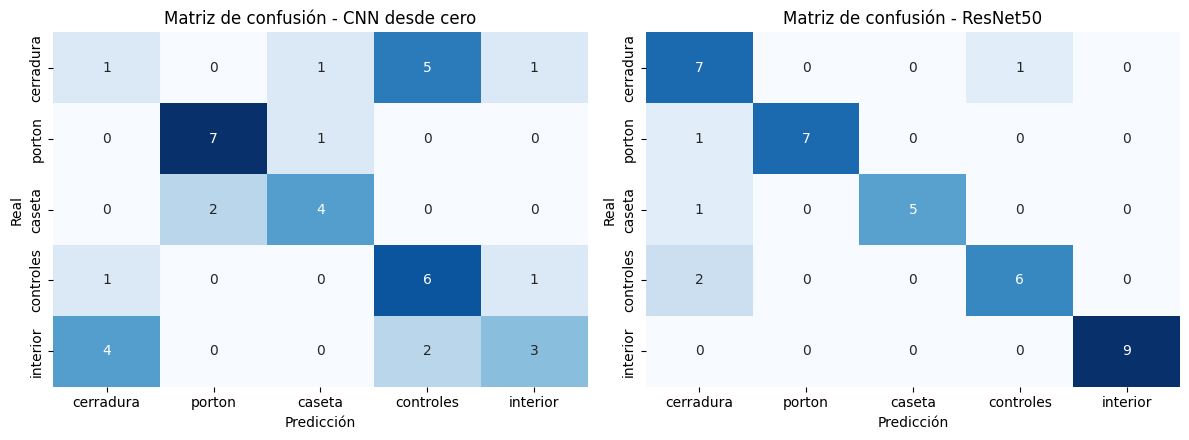

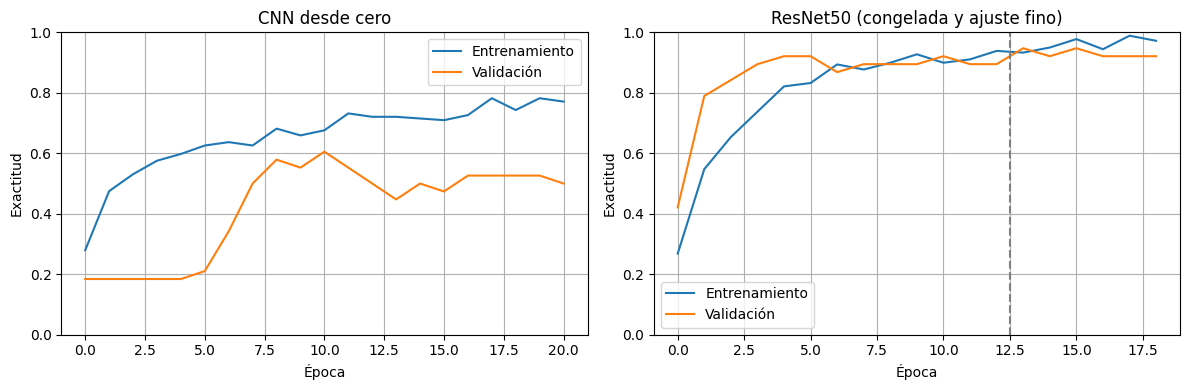

In [13]:
def evaluate(model, model_name):
    prob = model.predict(x_te, verbose=0)
    pred = prob.argmax(1)
    p, r_, f, _ = precision_recall_fscore_support(e_te, pred, average="macro", zero_division=0)
    return {"modelo": model_name, "accuracy": accuracy_score(e_te, pred), "precision_macro": p,
            "recall_macro": r_, "f1_macro": f}, pred, prob


cnn_metrics, pred_cnn, _ = evaluate(cnn_model, "CNN desde cero")
resnet_metrics, pred_res, prob_res = evaluate(resnet_model, "ResNet50 (transferencia + ajuste fino)")
vision_results = pd.DataFrame([cnn_metrics, resnet_metrics])
print(vision_results.round(3).to_string(index=False))
print(classification_report(e_te, pred_res, target_names=CLASSES, digits=3, zero_division=0))
vision_report = classification_report(e_te, pred_res, target_names=CLASSES, output_dict=True, zero_division=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, pr, t in [(axes[0], pred_cnn, "CNN desde cero"), (axes[1], pred_res, "ResNet50")]:
    sns.heatmap(confusion_matrix(e_te, pr, labels=range(5)), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title("Matriz de confusión - " + t); ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
plt.tight_layout(); plt.savefig("salidas/cm_vision.png", dpi=160); plt.show()

hist_total = {k: hist_res.history[k] + hist_ft.history[k] for k in ["accuracy", "val_accuracy", "loss", "val_loss"]}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, h, t in [(axes[0], hist_cnn.history, "CNN desde cero"), (axes[1], hist_total, "ResNet50 (congelada y ajuste fino)")]:
    ax.plot(h["accuracy"], label="Entrenamiento"); ax.plot(h["val_accuracy"], label="Validación")
    ax.set_title(t); ax.set_xlabel("Época"); ax.set_ylabel("Exactitud"); ax.set_ylim(0, 1); ax.grid(True); ax.legend()
axes[1].axvline(len(hist_res.history["loss"]) - 0.5, ls="--", c="gray")
plt.tight_layout(); plt.savefig("salidas/curvas_vision.png", dpi=140); plt.show()

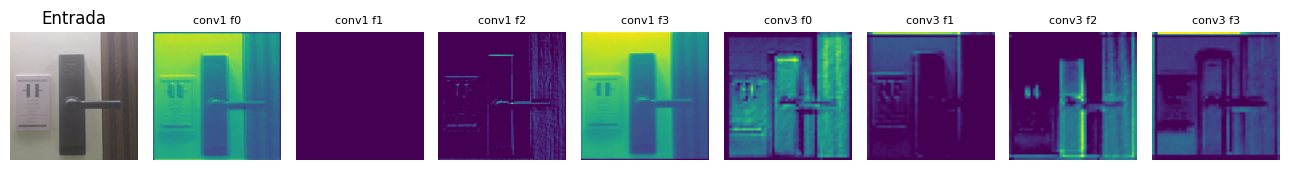

In [14]:
# Activation maps of the CNN from scratch (as in the class session): what the first convolutions detect
conv_layers = [c for c in cnn_model.layers if isinstance(c, layers.Conv2D)]
activation_model = models.Model(cnn_model.inputs, [c.output for c in conv_layers[:3:2]])
sample_idx = int(np.where(e_te == 0)[0][0])
feature_maps = activation_model.predict(x_te[sample_idx:sample_idx + 1], verbose=0)
fig = plt.figure(figsize=(13, 1.9))
plt.subplot(1, 9, 1); plt.imshow(x_te[sample_idx].astype("uint8")); plt.title("Entrada"); plt.axis("off")
for j in range(8):
    m = feature_maps[j // 4][0, :, :, j % 4]
    plt.subplot(1, 9, j + 2); plt.imshow(m, cmap="viridis"); plt.axis("off")
    plt.title(f"{'conv1' if j < 4 else 'conv3'} f{j % 4}", fontsize=8)
plt.tight_layout(); plt.savefig("salidas/activaciones.png", dpi=140); plt.show()

SUMMARY["vision"] = {"conteo": image_counts.to_dict(), "n_train": len(r_tr), "n_val": len(r_va), "n_test": len(r_te),
                     "modelos": vision_results.round(4).to_dict("records"),
                     "por_clase": {k: v for k, v in vision_report.items() if k in CLASSES},
                     "epocas": {"cnn": len(hist_cnn.history["loss"]), "resnet": len(hist_res.history["loss"]),
                                "ajuste_fino": len(hist_ft.history["loss"])}}
resnet_model.save("salidas/resnet50_hospedaje.keras")

## 7. Integración multimodal texto-imagen
1) El clasificador de intenciones etiqueta el texto. 2) ResNet50 etiqueta la foto. 3) Una política de decisión
combina ambas etiquetas y responde con la base de conocimiento del Avance 1 o escala a la anfitriona.
Regla clave: si el texto es ambiguo ("no me abre") la foto decide de qué acceso se trata.

In [15]:
RESPONSES = {  # reply texts carried over from Avance 1 (Cas'aguacate)
    "cerradura": "La puerta tiene cerradura electrónica: marca el código de 4 dígitos que te enviamos el día de llegada y presiona la palomita. Si parpadea en rojo, espera 1 minuto y vuelve a intentar.",
    "porton_estacionamiento": "El portón del estacionamiento se abre con el control que está en la caja junto a la entrada principal. Si no responde, presiona el botón 2 segundos frente al motor.",
    "acceso_fraccionamiento": "En la caseta indica que vas a Cas'aguacate, lote 12, y muestra tu identificación. El guardia registra tu placa.",
    "reportar_problema": "Gracias por avisar. Revisa que el control del minisplit tenga pilas y esté en modo frío (copo de nieve). Si sigue sin funcionar, la anfitriona te contacta en breve.",
    "llegada_tarde": "Sí, puedes llegar tarde sin problema: el acceso es con código y no necesitas que alguien te reciba.",
    "horarios": "Check-in desde las 15:00 y check-out a las 11:00.",
    "ubicacion": "Fraccionamiento Las Palmas (ficticio), Calle Ejemplo 123, a 10 minutos del centro.",
}
MESSAGES_ES = {"escalate": "Le paso tu mensaje a la anfitriona", "with_photo": " con la foto ({}).",
               "photo_issue": "Gracias por la foto. Le aviso a la anfitriona para que lo revise contigo.",
               "default": "Con gusto te ayudo; la anfitriona te confirma este dato."}
ESCALATE_INTENTS = {"early_late_checkout", "contactar_anfitrion"}
ACCESS_INTENTS = {"cerradura", "porton_estacionamiento", "acceso_fraccionamiento"}
IMAGE_TO_INTENT = {"cerradura": "cerradura", "porton": "porton_estacionamiento", "caseta": "acceso_fraccionamiento",
                      "controles": "reportar_problema", "interior": "reportar_problema"}
IMAGE_THRESHOLD = 0.60
AMBIGUOUS_TEXT = 0.60  # with a reliable photo, a text below this confidence lets the image decide


def classify_image(arr):
    prob = resnet_model.predict(arr[None, ...], verbose=0)[0]
    return CLASSES[int(prob.argmax())], float(prob.max())


def assist(text, image=None, classify=None, responses=None, messages=None):
    classify, responses, messages = classify or classify_text, responses or RESPONSES, messages or MESSAGES_ES
    intent, p = classify(text)
    image_class, q = classify_image(image) if image is not None else (None, 0.0)
    final_intent, decided_by = intent, "texto"
    if image_class and q >= IMAGE_THRESHOLD:
        suggested = IMAGE_TO_INTENT[image_class]
        if p < AMBIGUOUS_TEXT or (intent in ACCESS_INTENTS and suggested in ACCESS_INTENTS) or intent == "reportar_problema":
            final_intent, decided_by = suggested, ("imagen" if suggested != intent else "texto e imagen coinciden")
    if final_intent in ESCALATE_INTENTS or (p < TEXT_THRESHOLD and (image_class is None or q < IMAGE_THRESHOLD)):
        action, reply = "ESCALAR", messages["escalate"] + (messages["with_photo"].format(image_class) if image_class else ".")
    elif final_intent == "reportar_problema" and image_class == "interior":
        action, reply = "ESCALAR", messages["photo_issue"]
    else:
        action, reply = "RESPONDER", responses.get(final_intent, messages["default"])
    return {"texto": text, "intencion": intent, "conf_texto": round(p, 2), "imagen": image_class,
            "conf_imagen": round(q, 2), "decision_por": decided_by, "intencion_final": final_intent, "accion": action,
            "respuesta": reply}


def test_photo(image_class, n=0):
    return x_te[np.where(e_te == CLASSES.index(image_class))[0][n]]


cases = [("no me abre", "cerradura"), ("no me abre", "porton"), ("ya estoy aqui y no puedo pasar", "caseta"),
         ("hace mucho calor y no enfria", "controles"), ("mira como esta esto", "interior"),
         ("me puedo quedar mas tarde el domingo", None), ("a que hora es el check in", None),
         ("recomiendan algun restaurante por aca", None)]
results = pd.DataFrame([assist(t, test_photo(c) if c else None) for t, c in cases])
results.to_csv("salidas/integracion.csv", index=False)
SUMMARY["integracion"] = results.to_dict("records")
results[["texto", "intencion", "conf_texto", "imagen", "conf_imagen", "decision_por", "accion", "respuesta"]]

,texto,intencion,conf_texto,imagen,conf_imagen,decision_por,accion,respuesta
0,no me abre,cerradura,0.70,cerradura,1.00,texto e imagen coinciden,RESPONDER,La puerta tiene cerradura electrónica: marca e...
1,no me abre,cerradura,0.70,porton,1.00,imagen,RESPONDER,El portón del estacionamiento se abre con el c...
2,ya estoy aqui y no puedo pasar,reglas,0.15,caseta,1.00,imagen,RESPONDER,"En la caseta indica que vas a Cas'aguacate, l..."
3,hace mucho calor y no enfria,reportar_problema,0.72,controles,0.96,texto e imagen coinciden,RESPONDER,Gracias por avisar. Revisa que el control del ...
4,mira como esta esto,ubicacion,0.40,interior,1.00,imagen,ESCALAR,Gracias por la foto. Le aviso a la anfitriona ...
5,me puedo quedar mas tarde el domingo,early_late_checkout,0.79,None,0.00,texto,ESCALAR,Le paso tu mensaje a la anfitriona.
6,a que hora es el check in,horarios,0.87,None,0.00,texto,RESPONDER,Check-in desde las 15:00 y check-out a las 11:00.
7,recomiendan algun restaurante por aca,servicios,0.55,None,0.00,texto,RESPONDER,Con gusto te ayudo; la anfitriona te confirma ...


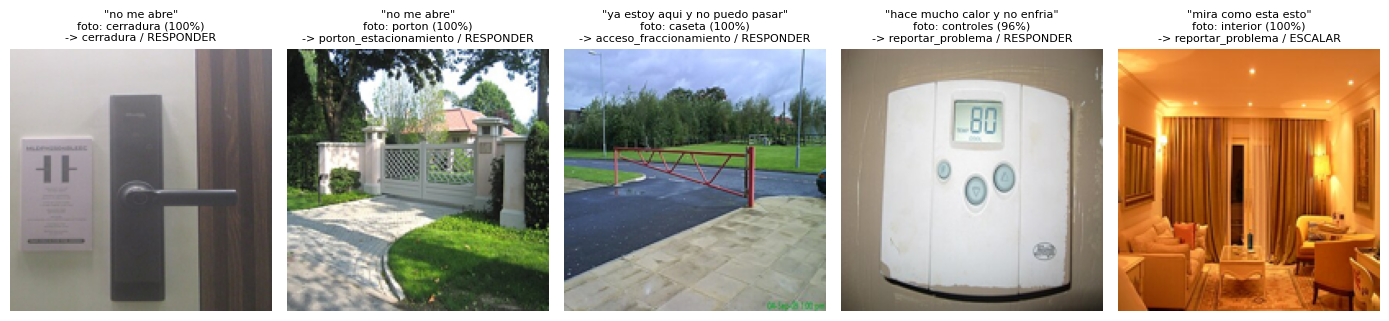

Listo: salidas/resumen.json


In [16]:
fig = plt.figure(figsize=(14, 3.6))
for i, (t, c) in enumerate(cases[:5]):
    s = results.iloc[i]
    plt.subplot(1, 5, i + 1); plt.imshow(test_photo(c).astype("uint8")); plt.axis("off")
    plt.title(f"\"{t}\"\nfoto: {s.imagen} ({s.conf_imagen:.0%})\n-> {s.intencion_final} / {s.accion}", fontsize=8)
plt.tight_layout(); plt.savefig("salidas/integracion.png", dpi=150); plt.show()

with open("salidas/resumen.json", "w") as f:
    json.dump(SUMMARY, f, ensure_ascii=False, indent=1, default=float)
print("Listo: salidas/resumen.json")

### Casos con foto fuera de dominio
La guía del proyecto pide probar un caso correcto, uno ambiguo y uno fuera de dominio. Aquí el huésped manda fotos que no
son de ninguna de las cinco clases: dos perros, dos platillos y dos automóviles de Wikimedia Commons con licencia libre
(créditos en `datos/fuera_de_dominio/creditos_fuera_de_dominio.csv`). El modelo no las vio nunca.

Las celdas de aquí en adelante se ejecutaron después del resto, con el mismo modelo ya entrenado (`salidas/resnet50_hospedaje.keras`), sin reentrenar.

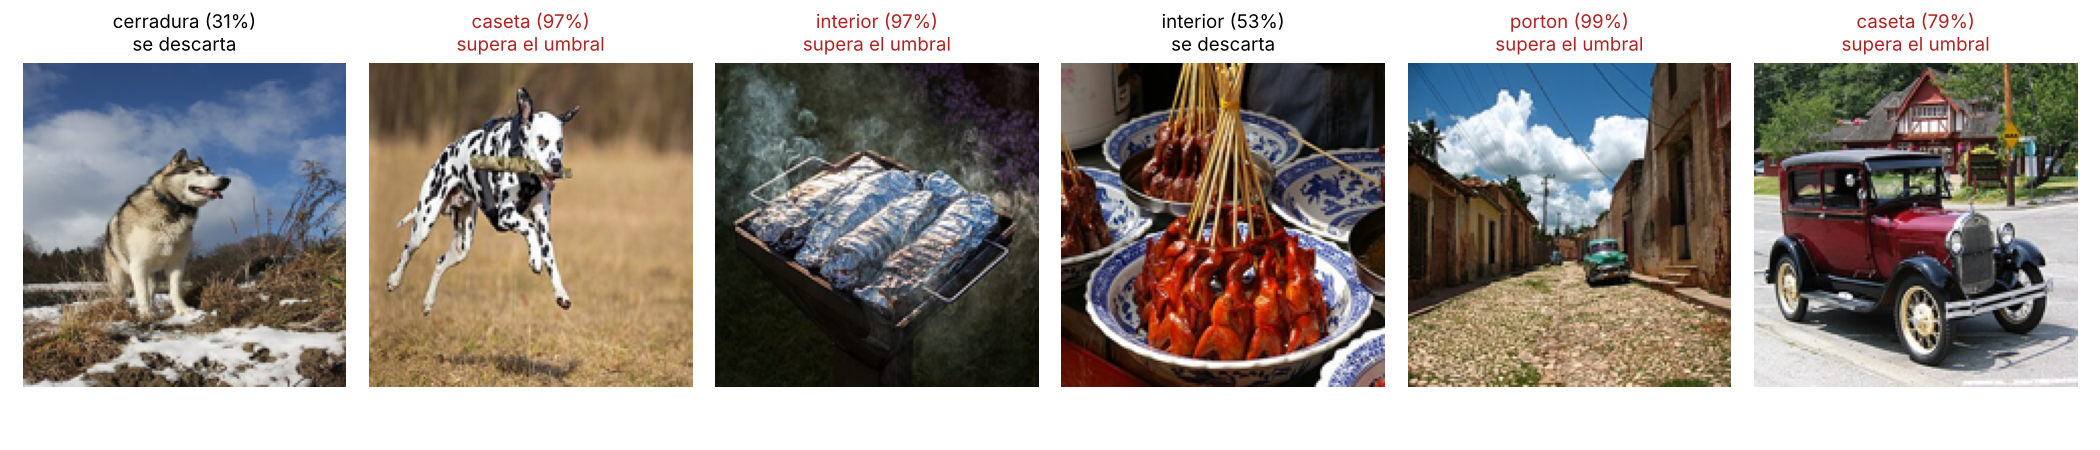

     archivo clase_predicha  confianza  supera_umbral
 perro_0.jpg      cerradura      0.313          False
 perro_1.jpg         caseta      0.966           True
comida_0.jpg       interior      0.966           True
comida_1.jpg       interior      0.525          False
  auto_0.jpg         porton      0.994           True
  auto_1.jpg         caseta      0.786           True
                  texto     archivo       intencion  conf_texto    imagen  conf_imagen decision_por        intencion_final    accion
puedo llevar a mi perro perro_0.jpg          reglas        0.76 cerradura         0.31        texto                 reglas RESPONDER
              mira esto perro_0.jpg saludo_cortesia        0.19 cerradura         0.31        texto        saludo_cortesia   ESCALAR
              mira esto perro_1.jpg saludo_cortesia        0.19    caseta         0.97       imagen acceso_fraccionamiento RESPONDER


In [17]:
def load_photo(path):
    return np.asarray(Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE)), dtype=np.float32)


OOD_DIR = "datos/fuera_de_dominio/"
ood_cases = [("puedo llevar a mi perro", "perro_0.jpg"), ("mira esto", "perro_0.jpg"), ("mira esto", "perro_1.jpg")]
ood = pd.DataFrame([{**assist(t, load_photo(OOD_DIR + f)), "archivo": f} for t, f in ood_cases])
ood.to_csv("salidas/integracion_fuera_de_dominio.csv", index=False)

ood_summary = []
plt.figure(figsize=(14, 3.0))
for i, f in enumerate(["perro_0.jpg", "perro_1.jpg", "comida_0.jpg", "comida_1.jpg", "auto_0.jpg", "auto_1.jpg"]):
    arr = load_photo(OOD_DIR + f)
    image_class, q = classify_image(arr)
    ood_summary.append({"archivo": f, "clase_predicha": image_class, "confianza": round(q, 3), "supera_umbral": bool(q >= IMAGE_THRESHOLD)})
    plt.subplot(1, 6, i + 1); plt.imshow(arr.astype("uint8")); plt.axis("off")
    plt.title(f"{image_class} ({q:.0%})\n" + ("supera el umbral" if q >= IMAGE_THRESHOLD else "se descarta"), fontsize=9,
              color=("firebrick" if q >= IMAGE_THRESHOLD else "black"))
plt.tight_layout(); plt.savefig("salidas/fuera_de_dominio.png", dpi=150); plt.show()

with open("salidas/fuera_de_dominio.json", "w") as f:
    json.dump({"umbral_imagen": IMAGE_THRESHOLD, "fotos": ood_summary, "casos": ood.to_dict("records")}, f,
              ensure_ascii=False, indent=1, default=float)
print(pd.DataFrame(ood_summary).to_string(index=False))
print(ood[["texto", "archivo", "intencion", "conf_texto", "imagen", "conf_imagen", "decision_por", "intencion_final", "accion"]].to_string(index=False))

### Prueba con fotos reales de Cas'aguacate
Nueve fotos de la galería pública del hospedaje, usadas con autorización de los anfitriones. El modelo se entrenó solo con
fotos genéricas de Wikimedia; estas son las primeras fotos reales del negocio que ve. No se reentrena: es una prueba.

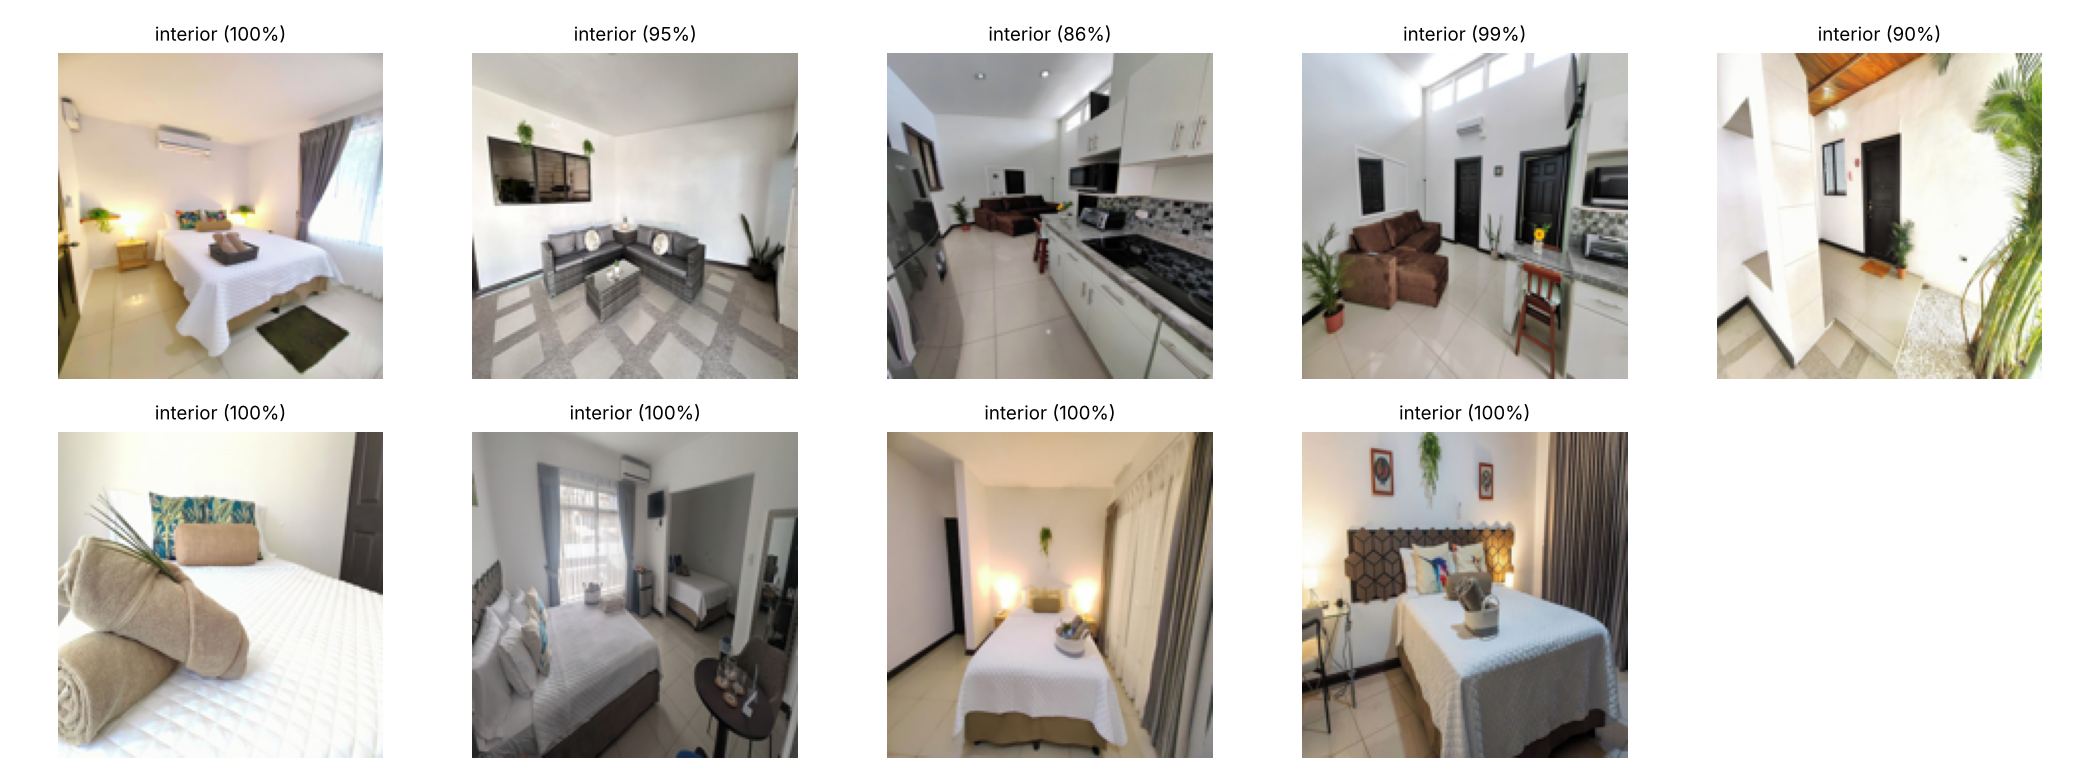

   archivo                                  descripcion                   esperada clase_predicha  confianza  acierta
real_1.jpg                 Recamara con cama y lamparas                   interior       interior      1.000     True
real_2.jpg                   Sala con sofa modular gris                   interior       interior      0.948     True
real_3.jpg                 Cocina con gabinetes blancos                   interior       interior      0.856     True
real_4.jpg                Sala con sofa cafe y cocineta                   interior       interior      0.991     True
real_5.jpg Pasillo con puerta negra y tapete de entrada ninguna (entrada exterior)       interior      0.903    False
real_6.jpg                Cama del apartamento familiar                   interior       interior      1.000     True
real_7.jpg                     Habitacion doble de lujo                   interior       interior      0.998     True
real_8.jpg                  Habitacion triple ejecutiva 

In [18]:
REAL_DIR = "datos/fotos_reales/"
real_photos = pd.read_csv(REAL_DIR + "origen_fotos_reales.csv")
real_rows = []
plt.figure(figsize=(14, 5.2))
for i, f in enumerate(real_photos["archivo"]):
    arr = load_photo(REAL_DIR + f)
    image_class, q = classify_image(arr)
    real_rows.append({"archivo": f, "clase_predicha": image_class, "confianza": round(q, 3)})
    plt.subplot(2, 5, i + 1); plt.imshow(arr.astype("uint8")); plt.axis("off")
    plt.title(f"{image_class} ({q:.0%})", fontsize=9)
plt.tight_layout(); plt.savefig("salidas/fotos_reales.png", dpi=150); plt.show()
real_results = real_photos[["archivo", "descripcion", "esperada"]].merge(pd.DataFrame(real_rows), on="archivo")
real_results["acierta"] = real_results["esperada"] == real_results["clase_predicha"]
interiors = real_results[real_results["esperada"] == "interior"]
with open("salidas/fotos_reales.json", "w") as f:
    json.dump({"fotos": json.loads(real_results.to_json(orient="records")), "interiores": int(len(interiors)),
               "interiores_acertados": int(interiors["acierta"].sum()),
               "interiores_sobre_umbral": int((interiors["acierta"] & (interiors["confianza"] >= IMAGE_THRESHOLD)).sum())},
              f, ensure_ascii=False, indent=1, default=float)
print(real_results.to_string(index=False))

### Funcionamiento bilingüe: español o inglés según el huésped
Igual que el chatbot del Avance 1, el asistente detecta el idioma del mensaje y contesta en ese idioma. La versión en español
es la que se documenta en este avance; aquí se agrega la versión en inglés: un corpus en inglés para las mismas 14
intenciones (`datos/corpus_intenciones_en.csv`), el mismo preprocesamiento con stopwords y stemmer del inglés, la misma
representación TF-IDF y la misma SVM calibrada. El clasificador visual no depende del idioma.

In [19]:
# English pipeline: same steps as the Spanish one, with English stopwords and stemmer
nltk.download("stopwords", quiet=True)
corpus_en = pd.read_csv("datos/corpus_intenciones_en.csv", sep="|")
KEEP_WORDS_EN = {"no", "not", "how", "where", "when", "what", "before", "after", "until", "from", "without", "can",
                 "late", "early", "more", "there"}
STOPWORDS_EN = set(stopwords.words("english")) - KEEP_WORDS_EN
stemmer_en = SnowballStemmer("english")


def preprocess_en(text: str, stem: bool = True, remove_stopwords: bool = True) -> str:
    tokens = [t for t in wordpunct_tokenize(normalize(text)) if t.isalnum()]
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOPWORDS_EN]
    if stem:
        tokens = [stemmer_en.stem(t) for t in tokens]
    return " ".join(tokens)


def to_features_en(text: str) -> pd.DataFrame:
    return pd.DataFrame({"norm": [preprocess_en(text, stem=False, remove_stopwords=False)], "proc": [preprocess_en(text)]})


corpus_en["norm"] = corpus_en["texto"].map(lambda t: preprocess_en(t, stem=False, remove_stopwords=False))
corpus_en["proc"] = corpus_en["texto"].map(preprocess_en)
X_en = corpus_en[["norm", "proc"]]
X_en_tr, X_en_te, y_en_tr, y_en_te = train_test_split(X_en, corpus_en["intencion"], test_size=0.2,
                                                      random_state=SEED, stratify=corpus_en["intencion"])
cv_en = cross_val_score(make_pipeline(tfidf(), LinearSVC(C=0.5, random_state=SEED)), X_en_tr, y_en_tr, cv=cv, scoring="f1_macro")
text_clf_en = make_pipeline(tfidf(), CalibratedClassifierCV(LinearSVC(C=0.5, random_state=SEED), cv=5)).fit(X_en_tr, y_en_tr)
pred_en = text_clf_en.predict(X_en_te)
print("English corpus:", len(corpus_en), "phrases |", corpus_en["intencion"].nunique(), "intents | test:", len(y_en_te))
print(classification_report(y_en_te, pred_en, zero_division=0, digits=3))


def classify_text_en(text: str):
    prob = text_clf_en.predict_proba(to_features_en(text))[0]
    i = int(np.argmax(prob))
    return text_clf_en.classes_[i], float(prob[i])

English corpus: 350 phrases | 14 intents | test: 70
                        precision    recall  f1-score   support

acceso_fraccionamiento      1.000     0.800     0.889         5
             cerradura      0.833     1.000     0.909         5
   contactar_anfitrion      0.833     1.000     0.909         5
        disponibilidad      0.625     1.000     0.769         5
   early_late_checkout      0.750     0.600     0.667         5
              horarios      1.000     0.600     0.750         5
         llegada_tarde      0.833     1.000     0.909         5
porton_estacionamiento      0.714     1.000     0.833         5
                reglas      0.500     0.600     0.545         5
     reportar_problema      0.333     0.200     0.250         5
       saludo_cortesia      1.000     1.000     1.000         5
             servicios      0.286     0.400     0.333         5
               tarifas      1.000     0.600     0.750         5
             ubicacion      1.000     0.400     0.5

In [20]:
# Language detection by function-word overlap (same idea as the Avance 1 chatbot); a tie keeps Spanish
ES_MARKERS = {"el", "la", "los", "las", "de", "del", "que", "y", "en", "un", "una", "es", "por", "para", "con", "mi", "se",
              "como", "donde", "cuando", "cuanto", "hay", "esta", "puedo", "al", "hola", "gracias", "buenas", "buenos",
              "tiene", "tienen", "quiero", "hora", "noche", "favor", "abre", "tarde", "ya", "estoy", "lo", "le", "su"}
EN_MARKERS = {"the", "is", "are", "do", "does", "you", "i", "we", "my", "our", "can", "how", "what", "where", "when",
              "there", "to", "of", "and", "in", "it", "for", "please", "hi", "hello", "thanks", "thank", "have", "not",
              "with", "at", "on", "this", "be", "will", "time", "night", "wont", "dont", "open", "late"}


def detect_language(text: str) -> str:
    tokens = wordpunct_tokenize(normalize(text))
    es = sum(t in ES_MARKERS for t in tokens)
    en = sum(t in EN_MARKERS for t in tokens)
    return "en" if en > es else "es"


RESPONSES_EN = {
    "cerradura": "The door has an electronic lock: enter the 4-digit code we sent you on arrival day and press the check mark. If it blinks red, wait 1 minute and try again.",
    "porton_estacionamiento": "The parking gate opens with the remote kept in the box next to the main entrance. If it does not respond, hold the button for 2 seconds in front of the motor.",
    "acceso_fraccionamiento": "At the security booth say you are going to Cas'aguacate, lot 12, and show your ID. The guard will register your license plate.",
    "reportar_problema": "Thanks for letting us know. Check that the AC remote has batteries and is set to cool mode (snowflake). If it still does not work, the host will contact you shortly.",
    "llegada_tarde": "Yes, you can arrive late with no problem: access is by code and nobody needs to be there to receive you.",
    "horarios": "Check-in from 15:00 and check-out at 11:00.",
    "ubicacion": "Las Palmas community (fictitious), 123 Example Street, 10 minutes from downtown.",
}
MESSAGES_EN = {"escalate": "I am passing your message to the host", "with_photo": " with the photo ({}).",
               "photo_issue": "Thanks for the photo. I am letting the host know so she can check it with you.",
               "default": "Happy to help; the host will confirm this for you."}


def assist_bilingual(text, image=None):
    """Routes the message to the Spanish or the English pipeline according to the guest's language."""
    lang = detect_language(text)
    if lang == "en":
        result = assist(text, image, classify=classify_text_en, responses=RESPONSES_EN, messages=MESSAGES_EN)
    else:
        result = assist(text, image)
    return {"idioma": lang, **result}


detection = {"es": float((corpus["texto"].map(detect_language) == "es").mean()),
             "en": float((corpus_en["texto"].map(detect_language) == "en").mean())}
print("Language detection accuracy:", {k: round(v, 3) for k, v in detection.items()})
bilingual_cases = [("no me abre", "cerradura"), ("the door wont open", "cerradura"), ("a que hora es el check in", None),
                   ("what time is check in", None), ("can we check out later, our flight is at night", None),
                   ("the ac is not cooling", "controles"), ("we will arrive around midnight, is that ok", None)]
bilingual = pd.DataFrame([assist_bilingual(t, test_photo(c) if c else None) for t, c in bilingual_cases])
bilingual.to_csv("salidas/integracion_bilingue.csv", index=False)
with open("salidas/bilingue.json", "w") as f:
    json.dump({"ingles": {"frases": len(corpus_en), "intenciones": int(corpus_en["intencion"].nunique()), "n_prueba": len(y_en_te),
                          "accuracy": accuracy_score(y_en_te, pred_en), "f1_macro": f1_score(y_en_te, pred_en, average="macro"),
                          "f1_macro_cv": cv_en.mean(), "f1_macro_cv_std": cv_en.std()},
               "deteccion_idioma": detection, "casos": json.loads(bilingual.to_json(orient="records"))}, f, ensure_ascii=False, indent=1, default=float)
print(bilingual[["texto", "idioma", "intencion", "conf_texto", "imagen", "conf_imagen", "intencion_final", "accion"]].to_string(index=False))

Language detection accuracy: {'es': 1.0, 'en': 0.966}
                                         texto idioma         intencion  conf_texto    imagen  conf_imagen   intencion_final    accion
                                    no me abre     es         cerradura        0.70 cerradura         1.00         cerradura RESPONDER
                            the door wont open     en         cerradura        0.67 cerradura         1.00         cerradura RESPONDER
                     a que hora es el check in     es          horarios        0.87       NaN         0.00          horarios RESPONDER
                         what time is check in     en          horarios        0.83       NaN         0.00          horarios RESPONDER
can we check out later, our flight is at night     en     llegada_tarde        0.42       NaN         0.00     llegada_tarde RESPONDER
                         the ac is not cooling     en reportar_problema        0.64 controles         0.96 reportar_problema RESPONDER
 